In [1]:
import gc                                # garbage collector, used to free RAM
import numpy as np                       # NumPy: numerical arrays
import pandas as pd                      # pandas: tables
import scanpy as sc                      # Scanpy: single-cell analysis (includes Scrublet)
import matplotlib.pyplot as plt          # matplotlib: plotting
from pathlib import Path                 # Path: file and folder paths

project_dir = Path.cwd().parent          # notebook lives in Notebook/, so parent = project root
proc_dir   = project_dir / "data" / "processed"
fig_dir    = project_dir / "Figure"
result_dir = project_dir / "Result"
fig_dir.mkdir(parents=True, exist_ok=True)
result_dir.mkdir(parents=True, exist_ok=True)

labels = ["D7", "D14", "D21"]
assert all((proc_dir / f"{s}_qc.h5ad").exists() for s in labels), "Missing *_qc.h5ad file(s) from notebook 04"

import skimage                           # scikit-image: needed for the automatic doublet threshold
print("scanpy", sc.__version__, "| scikit-image", skimage.__version__)

scanpy 1.11.5 | scikit-image 0.26.0


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_23076\1985312369.py:19: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", sc.__version__, "| scikit-image", skimage.__version__)


D7: 0 predicted doublets of 4,540 (0.0%), score cut-off ~ nan


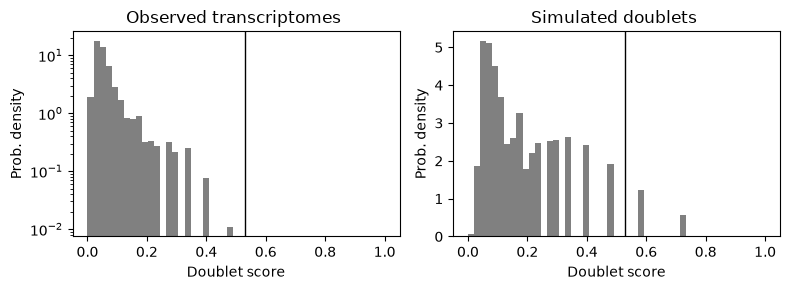

D14: 0 predicted doublets of 3,246 (0.0%), score cut-off ~ nan


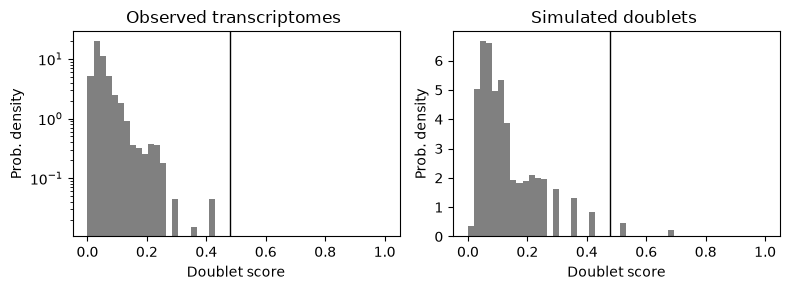

D21: 0 predicted doublets of 5,454 (0.0%), score cut-off ~ nan


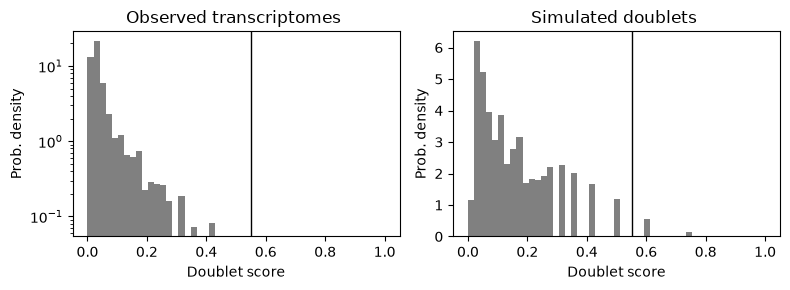

        sum  size
sample           
D14       0  3246
D21       0  5454
D7        0  4540


In [2]:
all_scores = []                                            # one small table per sample

for s in labels:
    a = sc.read_h5ad(proc_dir / f"{s}_qc.h5ad")            # QC-filtered cells of ONE sample (raw counts in .X)

    # Scrublet needs raw counts. It normalises and selects variable genes on an internal copy,
    # so our data stay untouched. expected_doublet_rate=0.05 is the Scanpy default (assumption).
    # random_state=0 makes the simulation reproducible.
    sc.pp.scrublet(a, expected_doublet_rate=0.05, random_state=0)

    # Adds a.obs["doublet_score"] (0 to 1) and a.obs["predicted_doublet"] (True/False)
    n_dbl = int(a.obs["predicted_doublet"].sum())          # number of cells called doublets
    called = a.obs.loc[a.obs["predicted_doublet"], "doublet_score"]
    cutoff = called.min() if len(called) else float("nan") # lowest score that was still called a doublet (approx. threshold)
    print(f"{s}: {n_dbl:,} predicted doublets of {a.n_obs:,} ({n_dbl / a.n_obs:.1%}), score cut-off ~ {cutoff:.3f}")

    # Left: scores of observed cells (log y). Right: scores of simulated doublets (linear y)
    fig = sc.pl.scrublet_score_distribution(a, return_fig=True, show=False)
    fig.savefig(fig_dir / f"scrublet_{s}.png", dpi=200, bbox_inches="tight")
    plt.show()

    t = a.obs[["doublet_score", "predicted_doublet"]].copy()   # keep only the two new columns
    t["sample"] = s                                            # barcodes can repeat across samples, so record the sample
    all_scores.append(t)

    del a                                                  # free memory before the next sample
    gc.collect()

scores = pd.concat(all_scores)
scores.to_csv(result_dir / "scrublet_scores.csv")           # index = barcode
print(scores.groupby("sample")["predicted_doublet"].agg(["sum", "size"]))

In [3]:
# Read the two small tables; the first column of each CSV is the barcode
scores = pd.read_csv(result_dir / "scrublet_scores.csv", index_col=0).rename_axis("barcode").reset_index()
qc = pd.read_csv(result_dir / "qc_metrics_before_filtering.csv", index_col=0).rename_axis("barcode").reset_index()
qc = qc.rename(columns={"timepoint": "sample"})        # use the same column name in both tables

# The same barcode sequence can occur in different samples, so match on barcode AND sample
df = scores.merge(qc, on=["barcode", "sample"], how="left")
print(int(df["total_counts"].isna().sum()), "cells without QC metrics (should be 0)")

for s in labels:
    d = df[df["sample"] == s].copy()                   # one sample at a time
    top_cut = d["doublet_score"].quantile(0.97)        # score above which a cell is in the top 3 %
    d["group"] = np.where(d["doublet_score"] >= top_cut, "top 3% score", "rest")
    print(f"\n{s}: doublet score of the top 3% starts at {top_cut:.3f}")
    # Median UMI and detected genes in the two groups (doublets usually have more of both)
    print(d.groupby("group")[["total_counts", "n_genes_by_counts"]].median().round(0))

0 cells without QC metrics (should be 0)

D7: doublet score of the top 3% starts at 0.198
              total_counts  n_genes_by_counts
group                                        
rest               30272.0             4736.0
top 3% score       53009.0             6295.0

D14: doublet score of the top 3% starts at 0.167
              total_counts  n_genes_by_counts
group                                        
rest               42583.0             6359.0
top 3% score       82020.0             8727.0

D21: doublet score of the top 3% starts at 0.196
              total_counts  n_genes_by_counts
group                                        
rest               23438.0             4250.0
top 3% score       37818.0             5756.0
